# Method bench 3, Phase G (greyscale): every arm alone, on 6 development tiles

**What this is.** The batch-D3 papers put into practice on the BT.601 grey tiles, each arm alone against the current
pipeline. Plan: `outputs/preregistration_method_bench_3.md` (written before any score). Numbers:
`evidence/pilot_scripts/method_bench_3/bench3_numbers.json`. Results write-up: `evidence/24_method_bench_3.md`. This notebook only **loads cached
outputs** (`/Volumes/USB2025/GeoAI-Descriptions/data/method_bench_3_cache/nb/`) and plots them; nothing is recomputed.

**Arms shown.**
- Gates (which pixels count as cloud; a road with ≥ 20% of its strip flagged is "cannot assess"): `rise` = production's
  dark-rise mask; **T1** Otsu on the grey rise (cut 108.8, the fallback, because η* = 0.547 < 0.65; the 0.65 is ours);
  **T1b** T1 + 2,500 m² blobs; **B1** EM/Bayes hysteresis per tile; **B1p** the same cuts pooled over training tiles;
  **B2** ICM-MRF (β 1.3; 1.6 and 1.8 are identical on the smoke tiles). **U1** (Dempster–Shafer) works per road, so it
  appears only in the road maps.
- Corrections (inside C0's gate, C0's 20 m fade, t < 0.2 left as is): **P1** Pan C-shift (C from the clear pre-storm
  date), **P1w** local C, **S1** sphere dark channel, **S1p** sphere + Pan's C, **M1** median dark channel, **L1**
  Poisson seam.
- Decision side: **Q1** (change ÷ t) and **PUL** (positive-unlabelled cut) change only the flood calls.

**How the tiles were chosen** (rule fixed in the preregistration before any result): the largest thin-cloud area, the
largest opaque share, a clear tile with the most roads, the tile with the most flooded roads, plus the smoke tiles.

**Colours in the road maps:** green = not flooded and called not flooded; blue = flooded and called flooded; red =
false flood call; orange = missed flood; grey = the arm's gate does not assess the road. Calls are seed 662 (the
spatial fold seed of the reproduction check); the road tables give the share of the 21 seeds that call each road
flooded.

In [1]:
import sys, json
sys.path.insert(0, '../../evidence/pilot_scripts/method_bench_3')
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 70
import nbviz as V
num = V.numbers('G')
kept = V.kept_table('G')
tiles = json.loads((V.NB / 'G_tiles.json').read_text())
print('tiles:', tiles['chosen'])

tiles: [['thin cloud', '0_13_5'], ['thick cloud', '0_11_4'], ['clear', '0_15_8'], ['flooded', '2_20_58'], ['smoke tile', '2_23_44'], ['smoke tile', '2_19_55']]


In [2]:
CORR = ['P1 Pan C tile', 'P1w Pan C local', 'S1 sphere DCP', 'S1p sphere + Pan C', 'M1 median DCP', 'L1 Poisson seam']
GATES = ['rise', 'T1', 'T1b', 'B1', 'B1p', 'B2-1.3']
GATE_ARMS = ['production', 'T1 Otsu grey rise', 'B1 EM-Bayes hysteresis', 'B1p EM-Bayes pooled', 'B2 ICM-MRF beta 1.3', 'U1 DS certain gate', 'U1s DS strict']
CORR_ARMS = ['production', 'C0 current two-date'] + CORR + ['Q1 1/t on C0 current two-date', 'PUL', 'PULb binned c']

### Thin cloud: tile `0_13_5`

This tile has the **largest thin-cloud area** of the Ida tiles: the ground is still visible through the haze. A good correction makes the hazy part look like the NOAA aerial photo (road edges and roofs with normal contrast and brightness, no grey veil, no dark blotches). In the |image − NOAA| maps, darker inside the cloud means closer to NOAA.

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 946,455 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- Not an Ida prep tile, so no NOAA view and no opaque share is listed.
- Touched roads: 16; labelled flooded: 0 (source: SN8 published labels via `sn8_heldout.touched_roads`).


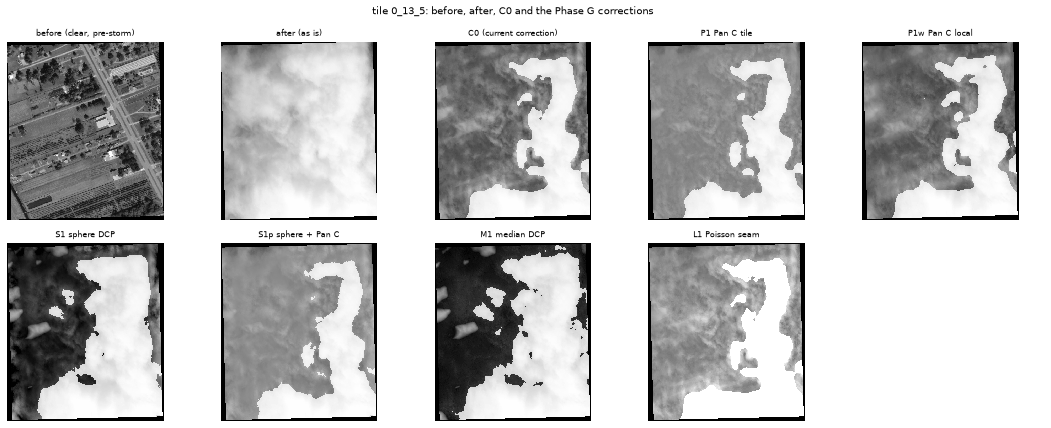

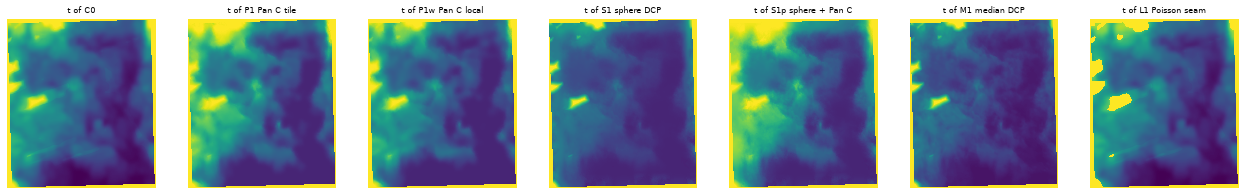

In [3]:
d = V.load('G', '0_13_5')
V.panel_images(d, CORR, 'tile 0_13_5: before, after, C0 and the Phase G corrections')
V.panel_t(d, CORR)

**Gate masks** (red = flagged as cloud). Compare each arm with production's `rise`.

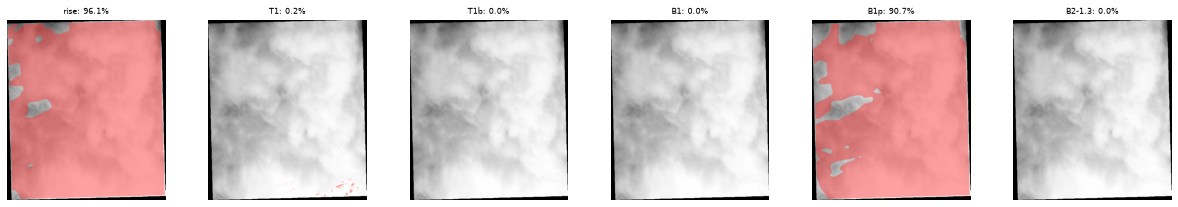

In [4]:
V.panel_masks(d, GATES)

**Against the NOAA aerial view** (|image − NOAA| inside the Ida score mask; the title number is the mean over C0's thin-cloud pixels on this tile, for orientation only: the scored statistic is the DINOv2 feature distance over all 54–73 tiles, in notebook 02).

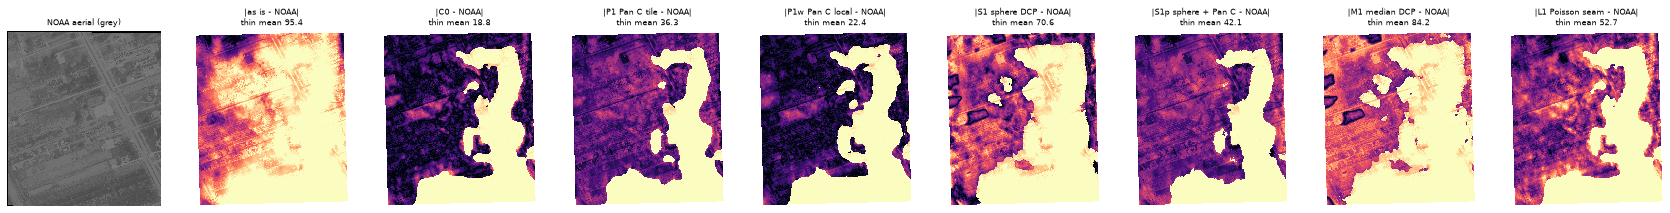

In [5]:
V.panel_noaa(d, CORR)

**Flood calls on the roads** (seed 662). Top: gates. Bottom: corrections and decision arms.

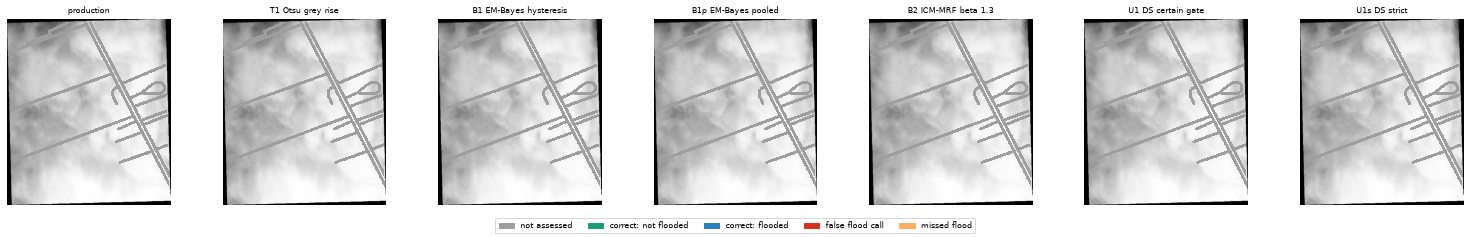

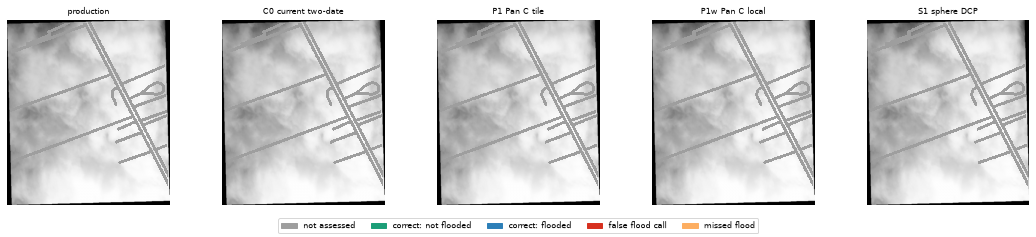

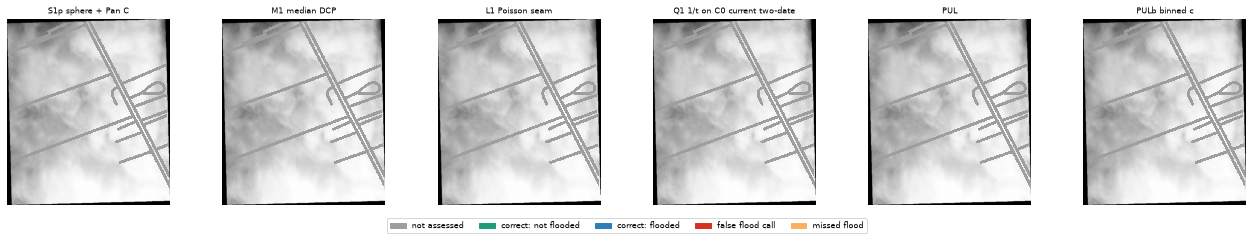

,road_id,flooded,production call@662,production flooded share (21 seeds),production assessed,B1 EM-Bayes hyster call@662,B1 EM-Bayes hyster flooded share (21 seeds),B1 EM-Bayes hyster assessed,U1 DS certain gate call@662,U1 DS certain gate flooded share (21 seeds),U1 DS certain gate assessed,P1 Pan C tile call@662,P1 Pan C tile flooded share (21 seeds),P1 Pan C tile assessed,PUL call@662,PUL flooded share (21 seeds),PUL assessed
0,way/847378451,0,0,0.00,0,0,0.00,0,0,0.0,0,0,0.00,0,0,0.00,0
1,way/847378452,0,0,0.00,0,0,0.00,0,0,0.0,0,0,0.00,0,0,0.00,0
2,way/847378463,0,0,0.14,0,1,0.14,0,0,0.0,0,0,0.57,0,0,0.29,0
3,way/847378464,0,0,0.00,0,0,0.00,0,0,0.0,0,0,0.00,0,0,0.00,0
4,way/847378465,0,0,0.00,0,0,0.00,0,0,0.0,0,0,0.00,0,0,0.00,0
5,way/847378670,0,0,0.00,0,0,0.00,0,0,0.0,0,0,0.00,0,0,0.00,0
6,way/847378675,0,0,0.00,0,0,0.00,0,0,0.0,0,0,0.00,0,0,0.00,0
7,way/847378676,0,0,0.00,0,0,0.00,0,0,0.0,0,0,0.00,0,0,0.00,0
8,way/847378677,0,0,0.00,0,0,0.00,0,0,0.0,0,0,0.00,0,0,0.00,0
9,way/847378678,0,0,0.00,0,0,0.00,0,0,0.0,0,0,0.00,0,0,0.00,0


In [6]:
V.panel_calls(d, GATE_ARMS, kept)
V.panel_calls(d, CORR_ARMS[:5], kept)
V.panel_calls(d, CORR_ARMS[5:], kept)
V.road_table(d, ['production', 'B1 EM-Bayes hysteresis', 'U1 DS certain gate', 'P1 Pan C tile', 'PUL'], kept)

### Thick cloud: tile `0_11_4`

This tile has the **largest opaque share** (t < 0.2). Nothing can be recovered under opaque cloud: a correction should leave it as it is, and a gate should flag it. Look for arms that paint dark patches into the cloud, and for gates that miss the core.

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 351,077 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- C0 opaque share of valid pixels: 9.7% (source: `BIG/tiles/0_11_4.pkl`, `c0_diag`).
- Touched roads: 3; labelled flooded: 0 (source: SN8 published labels via `sn8_heldout.touched_roads`).
- Share of valid pixels flagged: rise 33.1%, T1 5.6%, T1b 3.7%, B1 34.1%, B2-1.3 35.0%, B2-1.6 35.0%, B2-1.8 35.0%, B1p 26.8% (source: `BIG/tiles/0_11_4.pkl`).

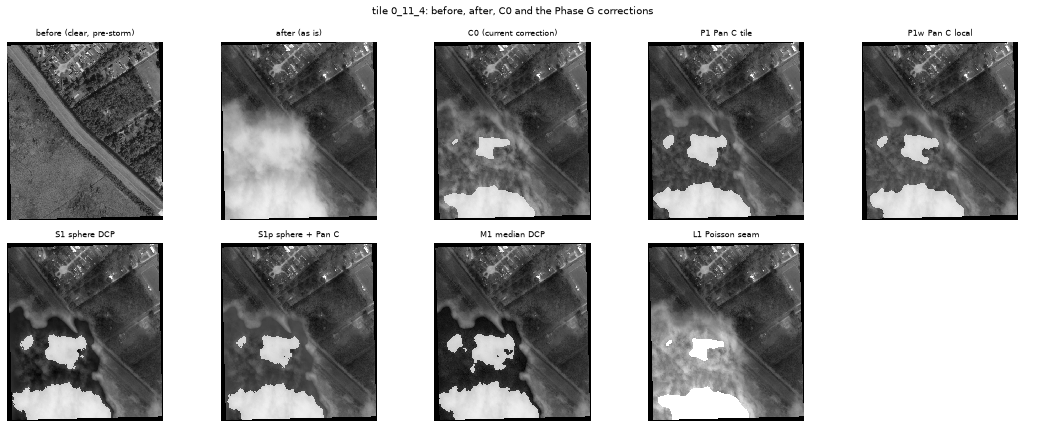

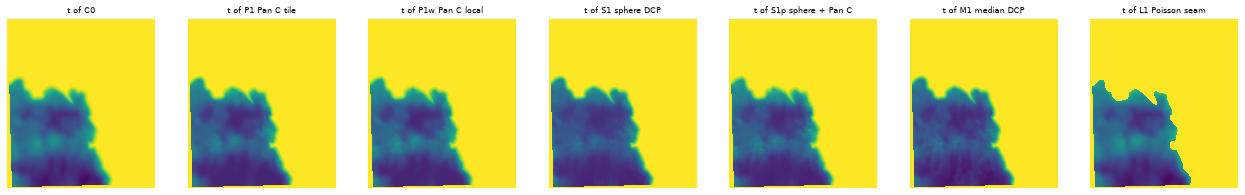

In [7]:
d = V.load('G', '0_11_4')
V.panel_images(d, CORR, 'tile 0_11_4: before, after, C0 and the Phase G corrections')
V.panel_t(d, CORR)

**Gate masks** (red = flagged as cloud). Compare each arm with production's `rise`.

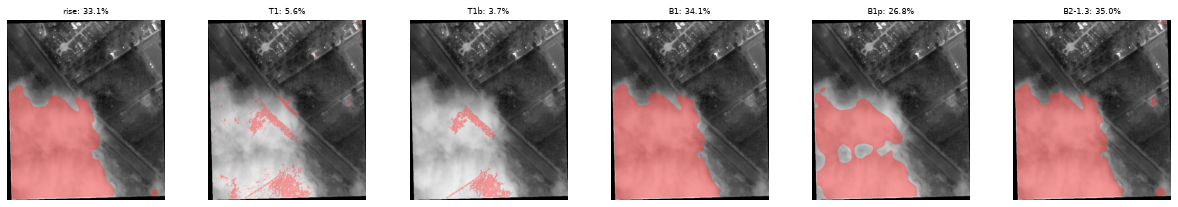

In [8]:
V.panel_masks(d, GATES)

**Against the NOAA aerial view** (|image − NOAA| inside the Ida score mask; the title number is the mean over C0's thin-cloud pixels on this tile, for orientation only: the scored statistic is the DINOv2 feature distance over all 54–73 tiles, in notebook 02).

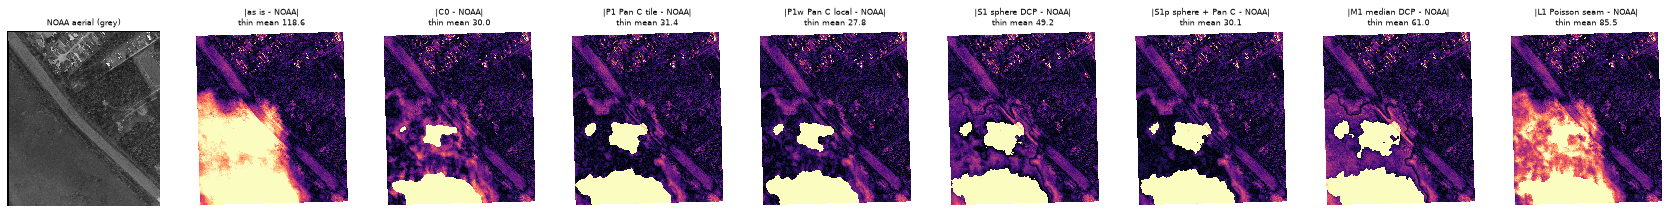

In [9]:
V.panel_noaa(d, CORR)

**Flood calls on the roads** (seed 662). Top: gates. Bottom: corrections and decision arms.

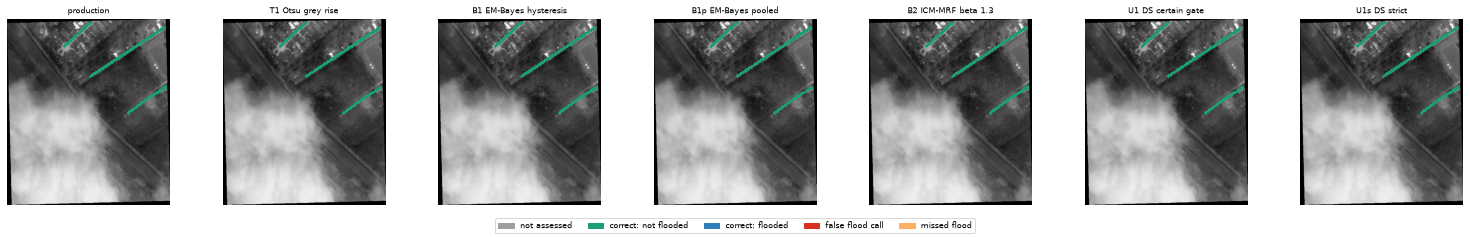

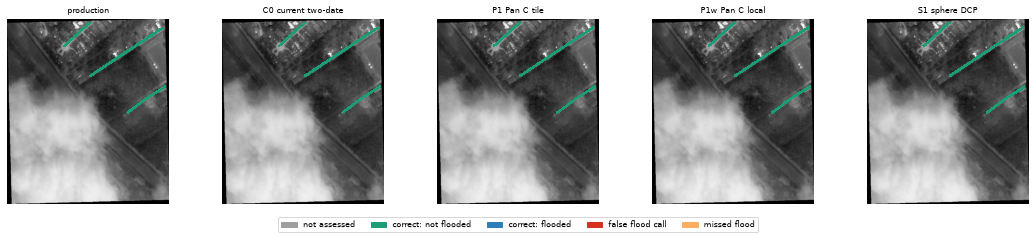

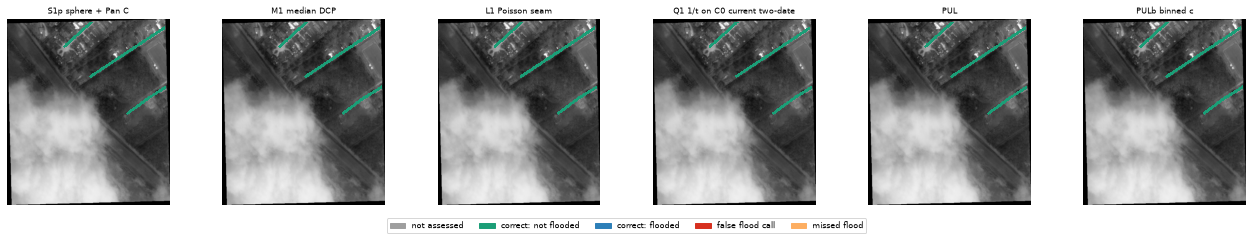

,road_id,flooded,production call@662,production flooded share (21 seeds),production assessed,B1 EM-Bayes hyster call@662,B1 EM-Bayes hyster flooded share (21 seeds),B1 EM-Bayes hyster assessed,U1 DS certain gate call@662,U1 DS certain gate flooded share (21 seeds),U1 DS certain gate assessed,P1 Pan C tile call@662,P1 Pan C tile flooded share (21 seeds),P1 Pan C tile assessed,PUL call@662,PUL flooded share (21 seeds),PUL assessed
0,way/847378455,0,0,0.0,1,0,0.0,1,0,0.0,1,0,0.0,1,0,0.0,1
1,way/847378476,0,0,0.0,1,0,0.0,1,0,0.0,1,0,0.0,1,0,0.0,1
2,way/847378477,0,0,0.0,1,0,0.0,1,0,0.0,1,0,0.0,1,0,0.0,1


In [10]:
V.panel_calls(d, GATE_ARMS, kept)
V.panel_calls(d, CORR_ARMS[:5], kept)
V.panel_calls(d, CORR_ARMS[5:], kept)
V.road_table(d, ['production', 'B1 EM-Bayes hysteresis', 'U1 DS certain gate', 'P1 Pan C tile', 'PUL'], kept)

### Clear: tile `0_15_8`

This is a **clear tile** (under 1% dark-rise and bright pixels). Every gate should flag (almost) nothing and every correction should leave the image unchanged. Any red in the gate panels is a false alarm.

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 0 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- C0 opaque share of valid pixels: 0.0% (source: `BIG/tiles/0_15_8.pkl`, `c0_diag`).
- Touched roads: 20; labelled flooded: 0 (source: SN8 published labels via `sn8_heldout.touched_roads`).
- Share of valid pixels flagged: rise 0.1%, T1 1.1%, T1b 0.0%, B1 3.1%, B2-1.3 11.8%, B2-1.6 11.8%, B2-1.8 11.8%, B1p 0.0% (source: `BIG/tiles/0_15_8.pkl`).

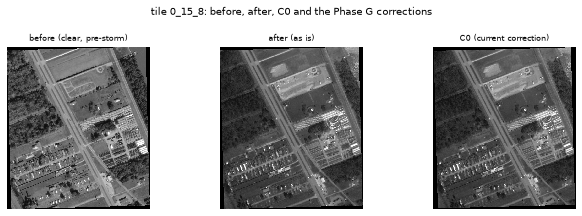

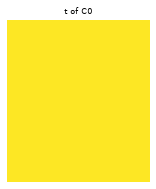

In [11]:
d = V.load('G', '0_15_8')
V.panel_images(d, CORR, 'tile 0_15_8: before, after, C0 and the Phase G corrections')
V.panel_t(d, CORR)

**Gate masks** (red = flagged as cloud). Compare each arm with production's `rise`.

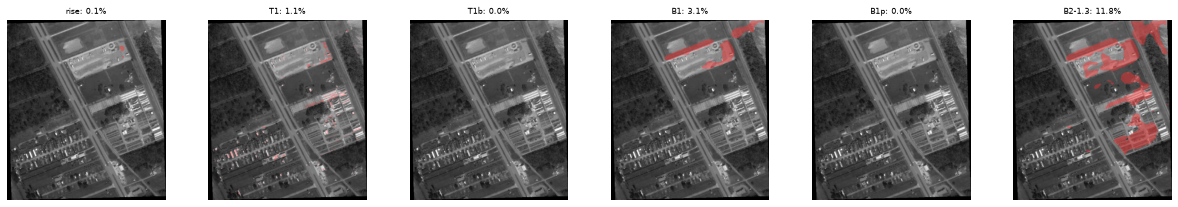

In [12]:
V.panel_masks(d, GATES)

**Against the NOAA aerial view** (|image − NOAA| inside the Ida score mask; the title number is the mean over C0's thin-cloud pixels on this tile, for orientation only: the scored statistic is the DINOv2 feature distance over all 54–73 tiles, in notebook 02).

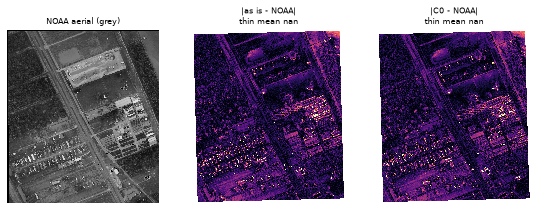

In [13]:
V.panel_noaa(d, CORR)

**Flood calls on the roads** (seed 662). Top: gates. Bottom: corrections and decision arms.

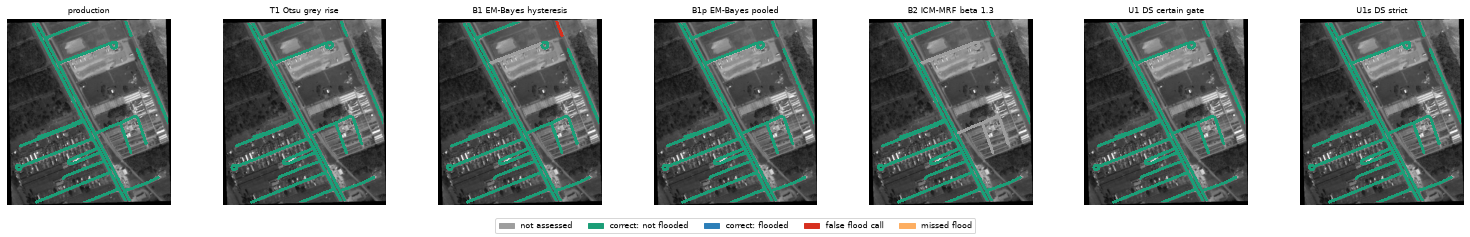

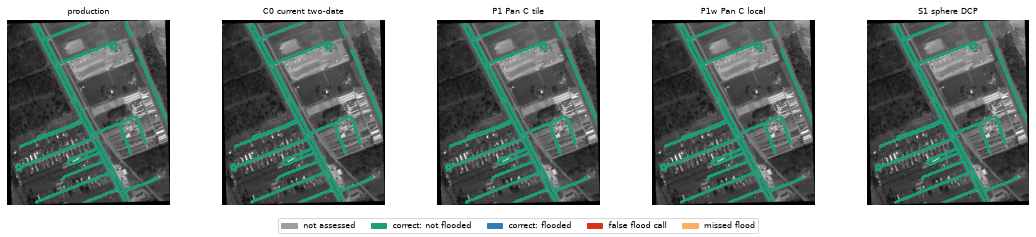

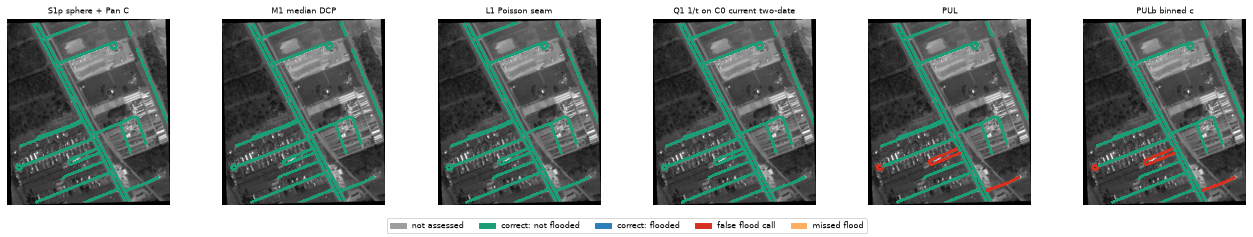

,road_id,flooded,production call@662,production flooded share (21 seeds),production assessed,B1 EM-Bayes hyster call@662,B1 EM-Bayes hyster flooded share (21 seeds),B1 EM-Bayes hyster assessed,U1 DS certain gate call@662,U1 DS certain gate flooded share (21 seeds),U1 DS certain gate assessed,P1 Pan C tile call@662,P1 Pan C tile flooded share (21 seeds),P1 Pan C tile assessed,PUL call@662,PUL flooded share (21 seeds),PUL assessed
0,way/847378451,0,0,0.0,1,0,0.00,1,0,0.0,1,0,0.0,1,0,0.00,1
1,way/847378452,0,0,0.0,1,0,0.00,1,0,0.0,1,0,0.0,1,0,0.00,1
2,way/847378707,0,0,0.0,1,0,0.00,1,0,0.0,1,0,0.0,1,0,0.00,1
3,way/847378708,0,0,0.0,1,0,0.00,1,0,0.0,1,0,0.0,1,0,0.00,1
4,way/847378709,0,0,0.0,1,0,0.00,0,0,0.0,1,0,0.0,1,0,0.00,1
5,way/847378714,0,0,0.0,1,1,0.05,1,0,0.0,1,0,0.0,1,0,0.38,1
6,way/847378451,0,0,0.0,1,0,0.00,1,0,0.0,1,0,0.0,1,0,0.00,1
7,way/847378452,0,0,0.0,1,0,0.00,1,0,0.0,1,0,0.0,1,0,0.00,1
8,way/847378710,0,0,0.0,1,0,0.00,1,0,0.0,1,0,0.0,1,0,0.00,1
9,way/847378711,0,0,0.0,1,0,0.00,1,0,0.0,1,0,0.0,1,0,0.00,1


In [14]:
V.panel_calls(d, GATE_ARMS, kept)
V.panel_calls(d, CORR_ARMS[:5], kept)
V.panel_calls(d, CORR_ARMS[5:], kept)
V.road_table(d, ['production', 'B1 EM-Bayes hysteresis', 'U1 DS certain gate', 'P1 Pan C tile', 'PUL'], kept)

### Flooded: tile `2_20_58`

This tile has the **most roads labelled flooded** among the tiles with a cloud gate. Check whether the flood calls (blue = flooded and called flooded, orange = flooded but missed, red = false flood call) change between arms, and whether a gate hides flooded roads (grey = not assessed).

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 0 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- Not an Ida prep tile, so no NOAA view and no opaque share is listed.
- Touched roads: 24; labelled flooded: 24 (source: SN8 published labels via `sn8_heldout.touched_roads`).
- Share of valid pixels flagged: rise 4.2%, T1 5.1%, T1b 0.0%, B1 15.8%, B2-1.3 20.5%, B2-1.6 20.5%, B2-1.8 20.5%, B1p 0.0% (source: `BIG/tiles/2_20_58.pkl`).

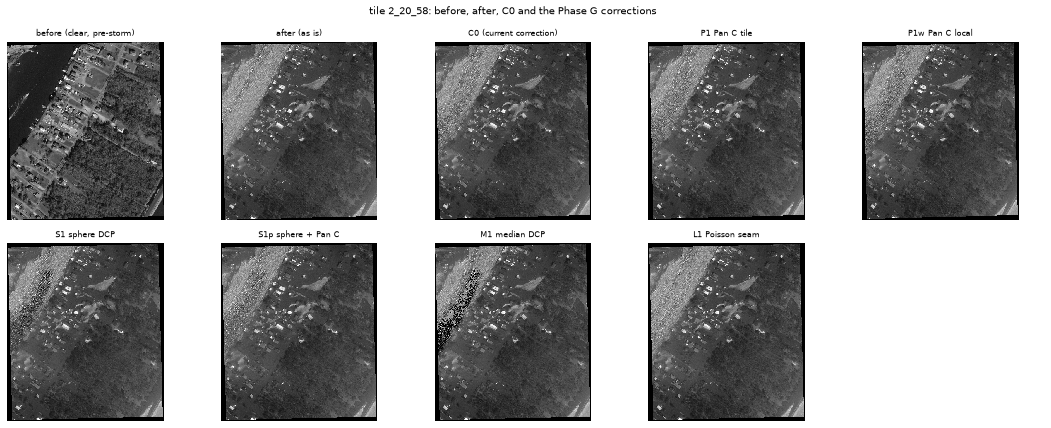

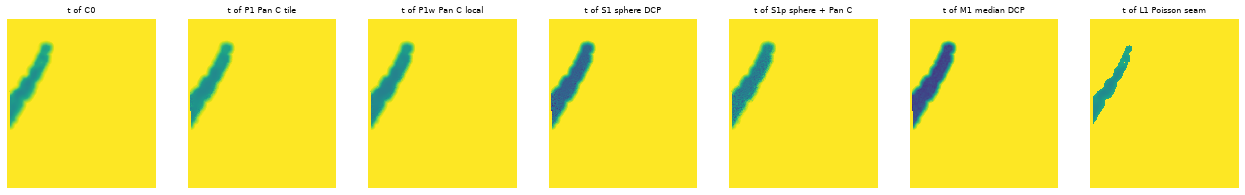

In [15]:
d = V.load('G', '2_20_58')
V.panel_images(d, CORR, 'tile 2_20_58: before, after, C0 and the Phase G corrections')
V.panel_t(d, CORR)

**Gate masks** (red = flagged as cloud). Compare each arm with production's `rise`.

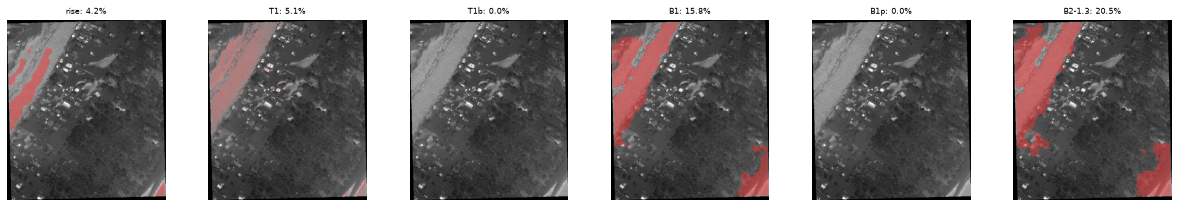

In [16]:
V.panel_masks(d, GATES)

**Against the NOAA aerial view** (|image − NOAA| inside the Ida score mask; the title number is the mean over C0's thin-cloud pixels on this tile, for orientation only: the scored statistic is the DINOv2 feature distance over all 54–73 tiles, in notebook 02).

In [17]:
V.panel_noaa(d, CORR)

No NOAA view for this tile (it is not among the Ida prep tiles).


**Flood calls on the roads** (seed 662). Top: gates. Bottom: corrections and decision arms.

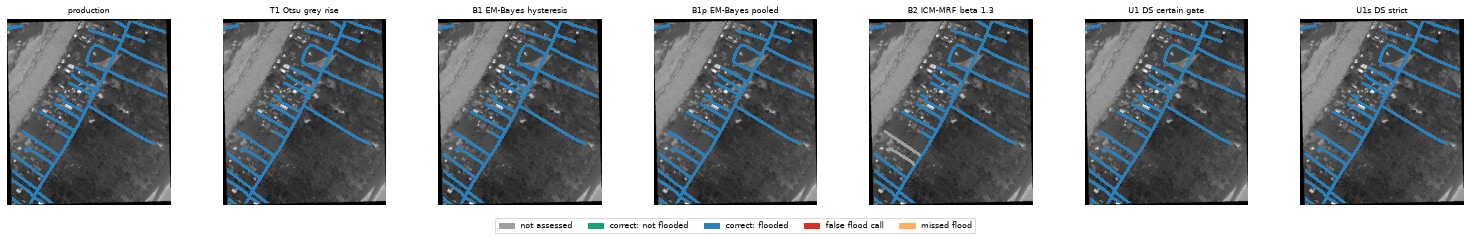

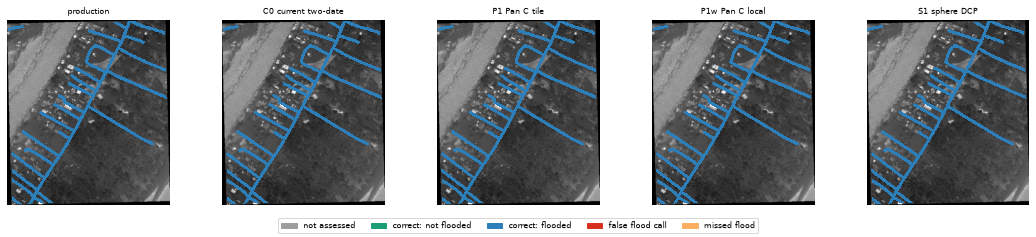

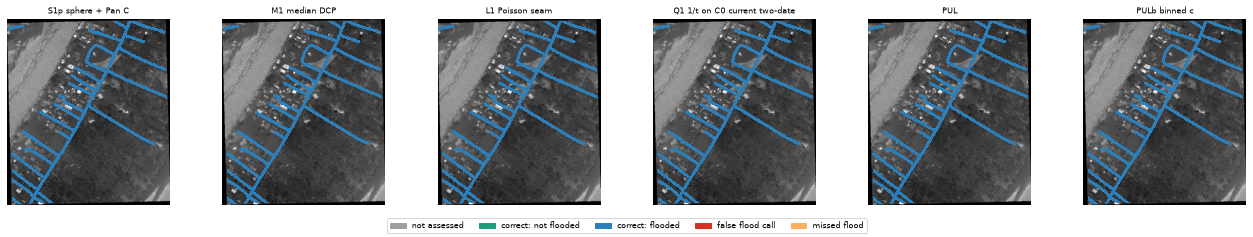

,road_id,flooded,production call@662,production flooded share (21 seeds),production assessed,B1 EM-Bayes hyster call@662,B1 EM-Bayes hyster flooded share (21 seeds),B1 EM-Bayes hyster assessed,U1 DS certain gate call@662,U1 DS certain gate flooded share (21 seeds),U1 DS certain gate assessed,P1 Pan C tile call@662,P1 Pan C tile flooded share (21 seeds),P1 Pan C tile assessed,PUL call@662,PUL flooded share (21 seeds),PUL assessed
0,way/847378310,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1
1,way/847378321,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1
2,way/847378323,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1
3,way/847378324,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1
4,way/847378325,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1
5,way/847378326,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1
6,way/847378327,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1
7,way/847378328,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1
8,way/847378329,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1
9,way/847378330,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1,1,1.0,1


In [18]:
V.panel_calls(d, GATE_ARMS, kept)
V.panel_calls(d, CORR_ARMS[:5], kept)
V.panel_calls(d, CORR_ARMS[5:], kept)
V.road_table(d, ['production', 'B1 EM-Bayes hysteresis', 'U1 DS certain gate', 'P1 Pan C tile', 'PUL'], kept)

### Smoke tile: tile `2_23_44`

One of the three **smoke-test tiles** (preregistration amendments). It is shown so the smoke notes can be checked against the images.

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 451,178 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- C0 opaque share of valid pixels: 4.5% (source: `BIG/tiles/2_23_44.pkl`, `c0_diag`).
- Touched roads: 3; labelled flooded: 2 (source: SN8 published labels via `sn8_heldout.touched_roads`).
- Share of valid pixels flagged: rise 38.4%, T1 9.6%, T1b 6.9%, B1 43.8%, B2-1.3 46.5%, B2-1.6 46.5%, B2-1.8 46.5%, B1p 23.2% (source: `BIG/tiles/2_23_44.pkl`).

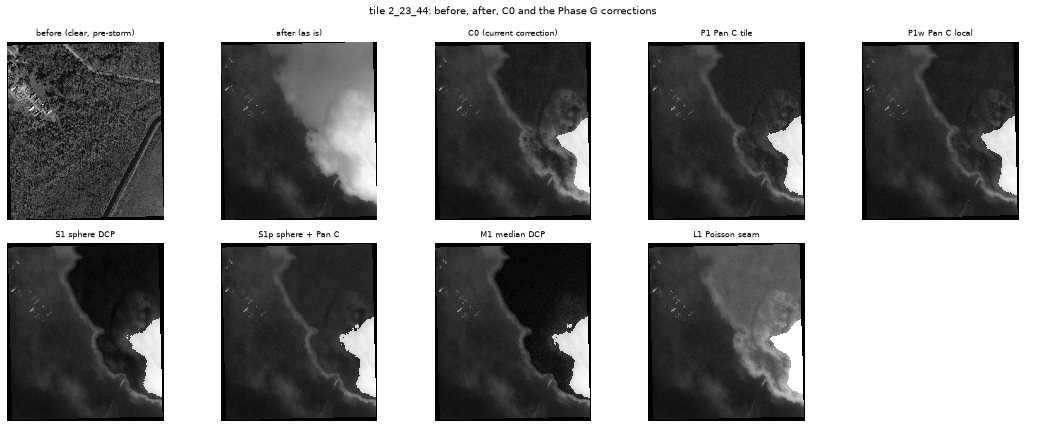

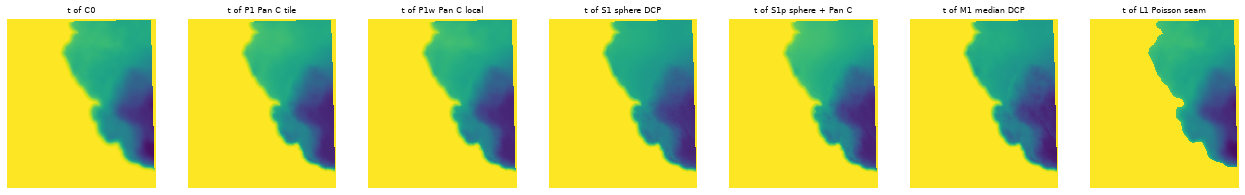

In [19]:
d = V.load('G', '2_23_44')
V.panel_images(d, CORR, 'tile 2_23_44: before, after, C0 and the Phase G corrections')
V.panel_t(d, CORR)

**Gate masks** (red = flagged as cloud). Compare each arm with production's `rise`.

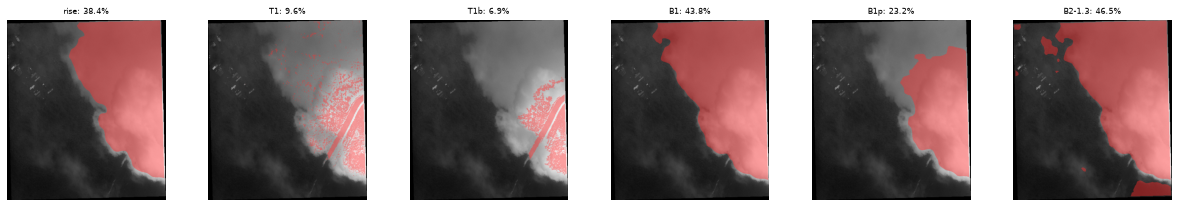

In [20]:
V.panel_masks(d, GATES)

**Against the NOAA aerial view** (|image − NOAA| inside the Ida score mask; the title number is the mean over C0's thin-cloud pixels on this tile, for orientation only: the scored statistic is the DINOv2 feature distance over all 54–73 tiles, in notebook 02).

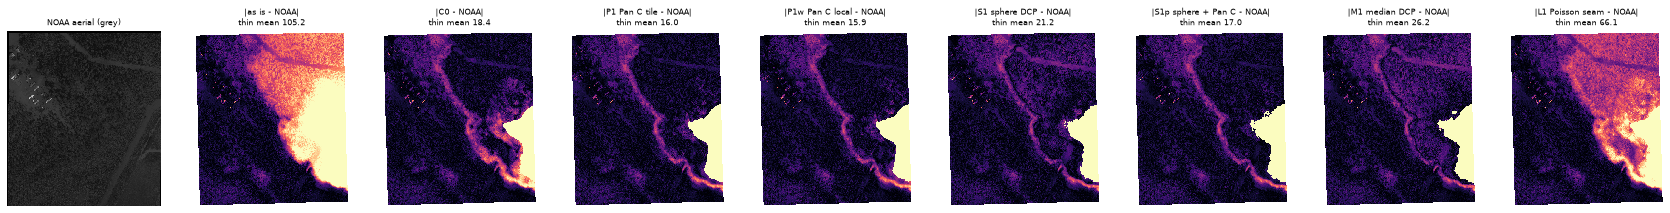

In [21]:
V.panel_noaa(d, CORR)

**Flood calls on the roads** (seed 662). Top: gates. Bottom: corrections and decision arms.

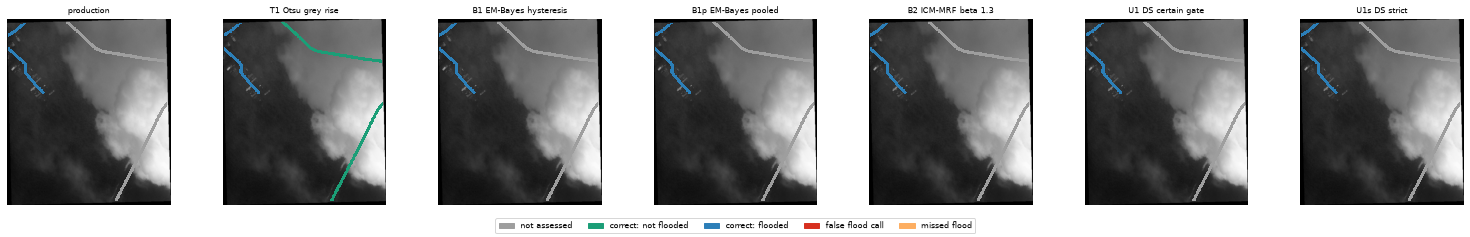

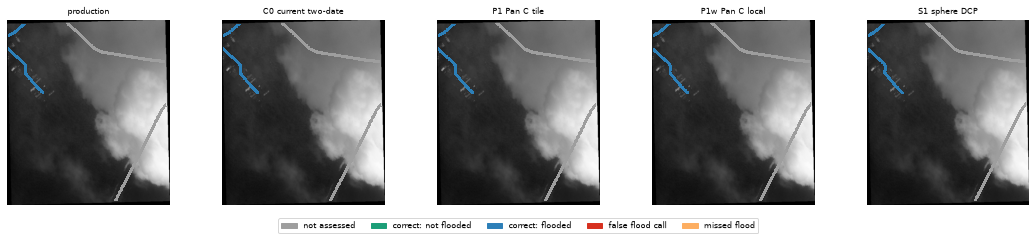

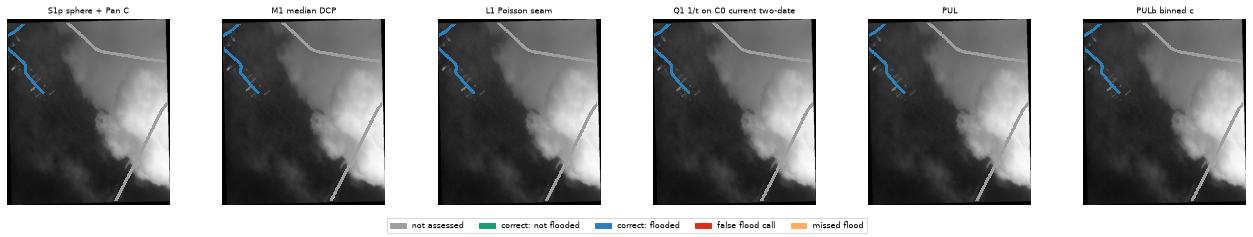

,road_id,flooded,production call@662,production flooded share (21 seeds),production assessed,B1 EM-Bayes hyster call@662,B1 EM-Bayes hyster flooded share (21 seeds),B1 EM-Bayes hyster assessed,U1 DS certain gate call@662,U1 DS certain gate flooded share (21 seeds),U1 DS certain gate assessed,P1 Pan C tile call@662,P1 Pan C tile flooded share (21 seeds),P1 Pan C tile assessed,PUL call@662,PUL flooded share (21 seeds),PUL assessed
0,way/847378248,0,0,0.00,0,0,0.00,0,0,0.00,0,0,0.00,0,0,0.0,0
1,way/847378914,1,1,1.00,1,1,1.00,1,1,1.00,1,1,1.00,1,1,1.0,1
2,way/847391451,1,1,0.86,1,1,0.95,1,1,0.81,1,1,0.81,1,1,1.0,1


In [22]:
V.panel_calls(d, GATE_ARMS, kept)
V.panel_calls(d, CORR_ARMS[:5], kept)
V.panel_calls(d, CORR_ARMS[5:], kept)
V.road_table(d, ['production', 'B1 EM-Bayes hysteresis', 'U1 DS certain gate', 'P1 Pan C tile', 'PUL'], kept)

### Smoke tile: tile `2_19_55`

One of the three **smoke-test tiles** (preregistration amendments). It is shown so the smoke notes can be checked against the images.

- Thin-cloud pixels (score ∩ C0 gate ∩ t ≥ 0.2): 213,187 (source: `evidence/pilot_scripts/method_bench_3/ida_rows_secondary.csv`).
- C0 opaque share of valid pixels: 0.3% (source: `BIG/tiles/2_19_55.pkl`, `c0_diag`).
- Touched roads: 6; labelled flooded: 6 (source: SN8 published labels via `sn8_heldout.touched_roads`).
- Share of valid pixels flagged: rise 29.7%, T1 0.0%, T1b 0.0%, B1 7.1%, B2-1.3 9.2%, B2-1.6 9.2%, B2-1.8 9.2%, B1p 7.2% (source: `BIG/tiles/2_19_55.pkl`).

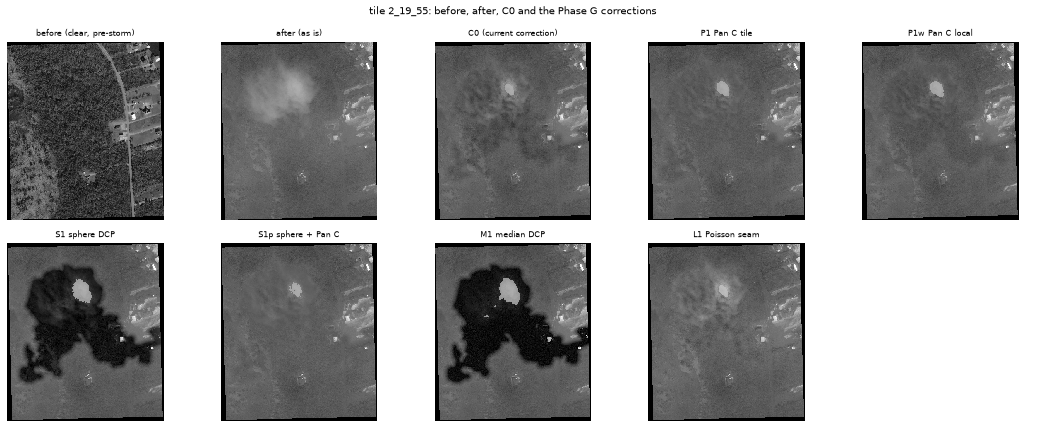

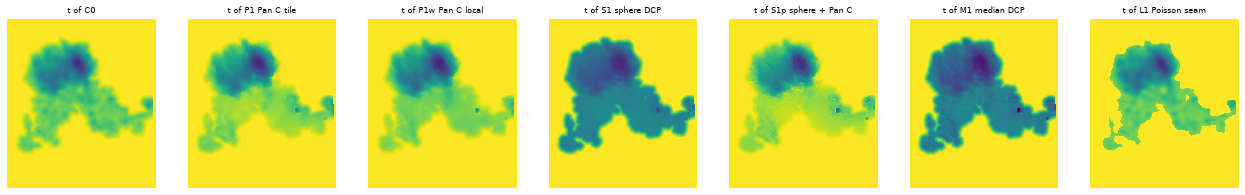

In [23]:
d = V.load('G', '2_19_55')
V.panel_images(d, CORR, 'tile 2_19_55: before, after, C0 and the Phase G corrections')
V.panel_t(d, CORR)

**Gate masks** (red = flagged as cloud). Compare each arm with production's `rise`.

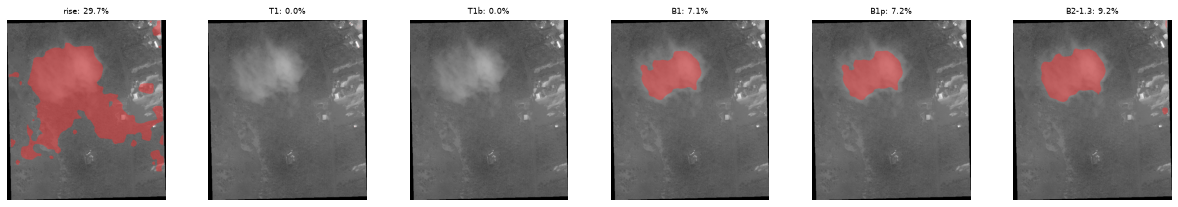

In [24]:
V.panel_masks(d, GATES)

**Against the NOAA aerial view** (|image − NOAA| inside the Ida score mask; the title number is the mean over C0's thin-cloud pixels on this tile, for orientation only: the scored statistic is the DINOv2 feature distance over all 54–73 tiles, in notebook 02).

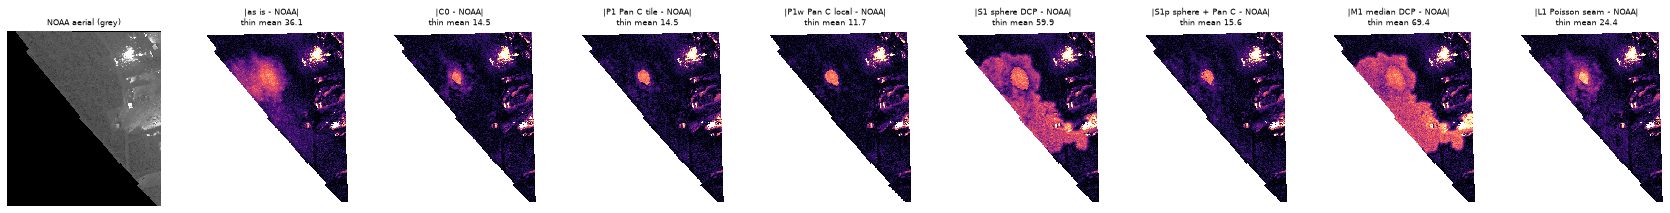

In [25]:
V.panel_noaa(d, CORR)

**Flood calls on the roads** (seed 662). Top: gates. Bottom: corrections and decision arms.

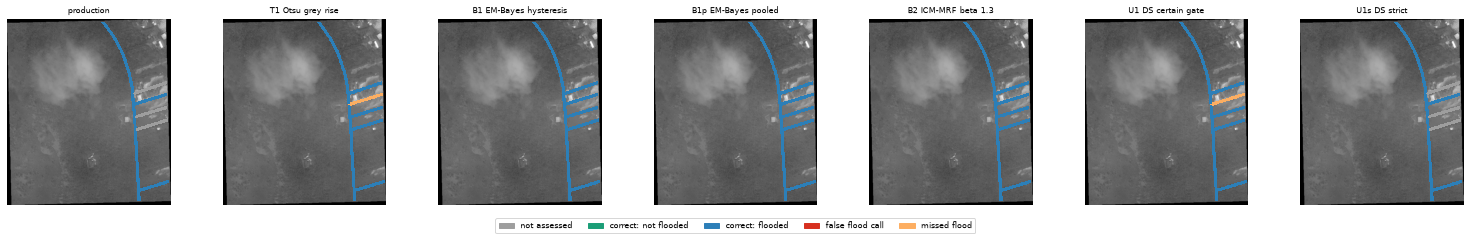

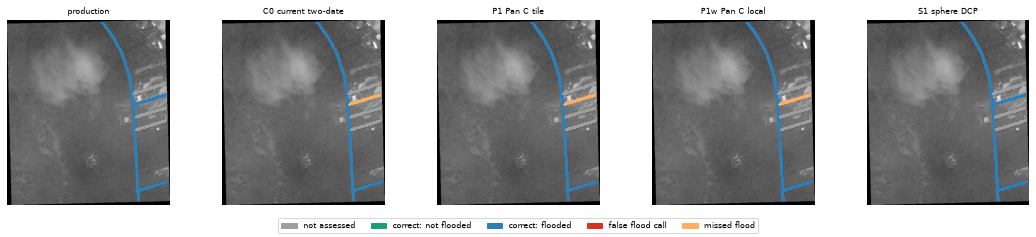

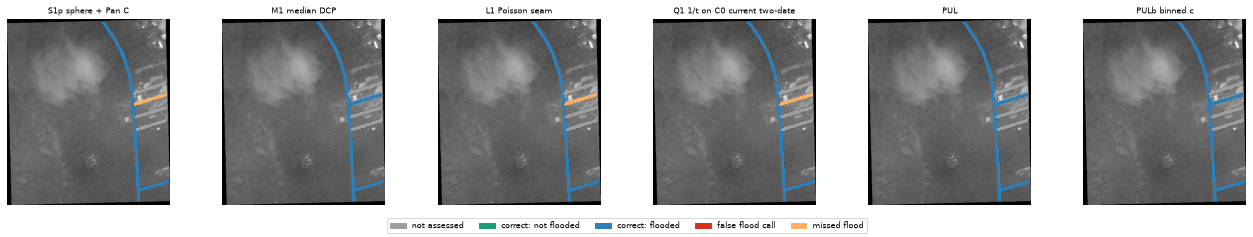

,road_id,flooded,production call@662,production flooded share (21 seeds),production assessed,B1 EM-Bayes hyster call@662,B1 EM-Bayes hyster flooded share (21 seeds),B1 EM-Bayes hyster assessed,U1 DS certain gate call@662,U1 DS certain gate flooded share (21 seeds),U1 DS certain gate assessed,P1 Pan C tile call@662,P1 Pan C tile flooded share (21 seeds),P1 Pan C tile assessed,PUL call@662,PUL flooded share (21 seeds),PUL assessed
0,way/847378370,1,1,1.00,1,1,1.00,1,1,1.00,1,1,1.00,1,1,1.0,1
1,way/847378417,1,1,1.00,0,1,1.00,1,1,1.00,1,1,1.00,0,1,1.0,0
2,way/847378418,1,1,0.90,0,1,0.90,1,1,0.90,1,0,0.71,0,1,1.0,0
3,way/847378419,1,1,0.76,1,1,0.62,1,0,0.33,1,0,0.05,1,1,1.0,1
4,way/847378420,1,1,0.90,0,1,0.95,1,1,0.86,1,1,1.00,0,1,1.0,0
5,way/847378422,1,1,1.00,1,1,1.00,1,1,1.00,1,1,1.00,1,1,1.0,1


In [26]:
V.panel_calls(d, GATE_ARMS, kept)
V.panel_calls(d, CORR_ARMS[:5], kept)
V.panel_calls(d, CORR_ARMS[5:], kept)
V.road_table(d, ['production', 'B1 EM-Bayes hysteresis', 'U1 DS certain gate', 'P1 Pan C tile', 'PUL'], kept)

## Each arm alone: the numbers behind the pictures
Flood gain = accuracy minus production's, in points, mean over 21 seeds on the roads both keep, with a 3 × 3 block
bootstrap 95% interval (source: `evidence/pilot_scripts/method_bench_3/bench3_numbers.json`, key `flood`). Ida = DINOv2 feature distance to NOAA in thin
cloud, arm minus C0, per tile (key `ida_primary_vs_C0`); negative = closer to NOAA.

In [27]:
rows = []
for n, r in num['flood'].items():
    s = r['seeds']
    rows.append({'arm': n, 'roads kept': r['kept'], 'added': r.get('added', 0), 'removed': r.get('removed', 0),
                 '21-seed gain (pts)': round(100 * s['mean_gain'], 2),
                 '95% interval': f"[{100 * s['ci'][0]:+.2f}, {100 * s['ci'][1]:+.2f}]",
                 'seeds better': s['seeds_better'], 'seeds worse': s['seeds_worse'],
                 'accuracy on added roads': (round(r['added_acc']['mean'], 3) if 'added_acc' in r else None)})
pd.DataFrame(rows)

,arm,roads kept,added,removed,21-seed gain (pts),95% interval,seeds better,seeds worse,accuracy on added roads
0,T1 Otsu grey rise,889,91,0,-0.08,"[-0.87, +0.93]",9,11,0.835
1,T1b Otsu grey rise + blob,891,93,0,-0.03,"[-0.87, +1.13]",9,11,0.839
2,B1 EM-Bayes hysteresis,804,34,28,0.45,"[-0.24, +1.11]",14,6,0.756
3,B1p EM-Bayes pooled,852,54,0,0.48,"[-0.26, +1.30]",17,2,0.757
4,B2 ICM-MRF beta 1.3,790,31,39,0.29,"[-0.40, +0.90]",13,8,0.762
5,B2 ICM-MRF beta 1.6,790,31,39,0.29,"[-0.40, +0.90]",13,8,0.762
6,B2 ICM-MRF beta 1.8,790,31,39,0.29,"[-0.40, +0.90]",13,8,0.762
7,U1 DS certain gate,876,78,0,0.02,"[-0.74, +1.04]",9,11,0.835
8,U1s DS strict,795,0,3,0.20,"[-0.13, +0.45]",12,8,NaN
9,C0 current two-date,798,0,0,-0.57,"[-1.31, +0.15]",1,17,NaN


In [28]:
rows = []
for a, r in (num.get('ida_primary_vs_C0') or {}).items():
    if r:
        g = (num.get('ida_grey_err_thin_vs_C0') or {}).get(a)
        rows.append({'arm': a, 'tiles': r['tiles'], 'feature distance vs C0': round(r['mean_diff'], 4),
                     '95% interval': f"[{r['ci'][0]:+.4f}, {r['ci'][1]:+.4f}]", 'guard ok': r.get('guard_ok'),
                     'grey error thin vs C0': (round(g['mean_diff'], 1) if g else None)})
pd.DataFrame(rows)

,arm,tiles,feature distance vs C0,95% interval,guard ok,grey error thin vs C0
0,as is,73,-0.0048,"[-0.0150, +0.0071]",False,46.5
1,P1 Pan C tile,73,-0.0007,"[-0.0063, +0.0043]",True,-1.0
2,P1w Pan C local,73,0.0020,"[-0.0025, +0.0066]",True,-1.3
3,S1 sphere DCP,73,0.0309,"[+0.0200, +0.0421]",False,16.3
4,S1p sphere + Pan C,73,0.0098,"[+0.0012, +0.0188]",True,-0.7
5,M1 median DCP,73,0.0250,"[+0.0114, +0.0376]",False,27.6
6,L1 Poisson seam,73,-0.0065,"[-0.0166, +0.0021]",True,29.2
